In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/healthcare_data_for_task - healthcare_data_for_task.csv")

In [ ]:
df.head()

,Patient_ID,Age,Gender,Blood_Type,Medical_Condition,Medical_Code,Date_of_Admission,Discharge_Date,Admission_Type,Billing_Amount
0,P0001,47,Male,AB+,Heart Disease,HEA004,2025-05-10,2025-05-16,Emergency,23218.31
1,P0002,62,Female,AB-,Diabetes,DIA001,2025-12-31,2026-01-02,Emergency,47010.56
2,P0003,36,Male,AB-,Heart Disease,HEA004,2025-11-10,2025-11-27,Emergency,39619.01
3,P0004,51,Male,A+,Heart Disease,HEA004,2023-05-02,2023-05-07,Elective,35963.71
4,P0005,30,Male,A+,Diabetes,DIA001,2024-04-11,2024-04-17,Urgent,64615.93


In [ ]:
df.shape

(1000, 10)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         1000 non-null   object 
 1   Age                1000 non-null   int64  
 2   Gender             1000 non-null   object 
 3   Blood_Type         1000 non-null   object 
 4   Medical_Condition  1000 non-null   object 
 5   Medical_Code       970 non-null    object 
 6   Date_of_Admission  1000 non-null   object 
 7   Discharge_Date     1000 non-null   object 
 8   Admission_Type     1000 non-null   object 
 9   Billing_Amount     1000 non-null   float64
dtypes: float64(1), int64(1), object(8)
memory usage: 78.3+ KB


In [ ]:
df.describe()

,Age,Billing_Amount
count,1000.000000,1000.000000
mean,51.888000,77117.515720
std,19.256954,41955.242269
min,18.000000,5568.160000
25%,35.750000,40318.785000
50%,52.000000,77293.900000
75%,69.000000,113089.267500
max,85.000000,149921.800000


In [ ]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Blood_Type', 'Medical_Condition',
       'Medical_Code', 'Date_of_Admission', 'Discharge_Date', 'Admission_Type',
       'Billing_Amount'],
      dtype='object')

In [ ]:
df['Age']
df['Medical_Code']

,Medical_Code
0,HEA004
1,DIA001
2,HEA004
3,HEA004
4,DIA001
...,...
995,DIA001
996,DIA001
997,DIA001
998,DIA001


In [ ]:
df.isnull().sum()

,0
Patient_ID,0
Age,0
Gender,0
Blood_Type,0
Medical_Condition,0
Medical_Code,30
Date_of_Admission,0
Discharge_Date,0
Admission_Type,0
Billing_Amount,0


In [ ]:
df['Medical_Code'] = df['Medical_Code'].fillna('Unknown')

In [ ]:
df['Admission_Type']=(
    df['Admission_Type'].str.strip().str.title()
)

In [ ]:
df['Admission_Type'].unique()

array(['Emergency', 'Elective', 'Urgent'], dtype=object)

In [ ]:
df['Admission_Type'].value_counts()

,count
Admission_Type,
Emergency,381
Elective,368
Urgent,251


In [ ]:
df['Date_of_Admission']=pd.to_datetime(df['Date_of_Admission'])

In [ ]:
df['Discharge_Date']=pd.to_datetime(df['Discharge_Date'])

In [ ]:
print(df['Date_of_Admission'].dt.year)

0      2025
1      2025
2      2025
3      2023
4      2024
       ... 
995    2023
996    2025
997    2023
998    2023
999    2023
Name: Date_of_Admission, Length: 1000, dtype: int32


In [ ]:
print(df['Date_of_Admission'].dt.month)

0       5
1      12
2      11
3       5
4       4
       ..
995     3
996     4
997     5
998     2
999     2
Name: Date_of_Admission, Length: 1000, dtype: int32


In [ ]:
print(df['Date_of_Admission'].dt.day)

0      10
1      31
2      10
3       2
4      11
       ..
995    16
996    17
997     8
998    11
999    10
Name: Date_of_Admission, Length: 1000, dtype: int32


In [ ]:
df['Stay_days']=(
    df['Discharge_Date']
    -df['Date_of_Admission']
    ).dt.days

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Patient_ID         1000 non-null   object        
 1   Age                1000 non-null   int64         
 2   Gender             1000 non-null   object        
 3   Blood_Type         1000 non-null   object        
 4   Medical_Condition  1000 non-null   object        
 5   Medical_Code       1000 non-null   object        
 6   Date_of_Admission  1000 non-null   datetime64[ns]
 7   Discharge_Date     1000 non-null   datetime64[ns]
 8   Admission_Type     1000 non-null   object        
 9   Billing_Amount     1000 non-null   float64       
 10  Stay_days          1000 non-null   int64         
dtypes: datetime64[ns](2), float64(1), int64(2), object(6)
memory usage: 86.1+ KB


In [ ]:
df['Billing_Amount'].describe()

,Billing_Amount
count,1000.000000
mean,77117.515720
std,41955.242269
min,5568.160000
25%,40318.785000
50%,77293.900000
75%,113089.267500
max,149921.800000


In [ ]:
df.groupby('Medical_Condition')['Age'].mean()

,Age
Medical_Condition,
Arthritis,52.674641
Asthma,49.919598
Diabetes,53.130653
Heart Disease,52.180995
Hypertension,51.395349


In [ ]:
pd.crosstab(
    df['Medical_Condition'],
    df['Gender']
)

Gender,Female,Male
Medical_Condition,,
Arthritis,95,114
Asthma,101,98
Diabetes,110,89
Heart Disease,104,117
Hypertension,80,92


<Axes: xlabel='Admission_Type'>

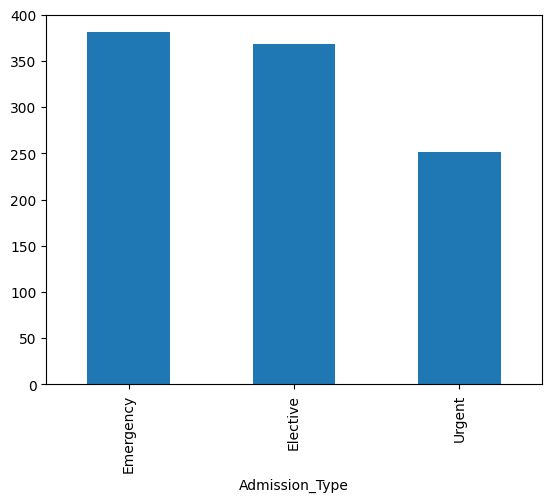

In [ ]:
df['Admission_Type'].value_counts().plot(kind='bar')

In [ ]:
billing_summary=(
    df.groupby(['Medical_Condition','Admission_Type'])['Billing_Amount'].sum().unstack()
)





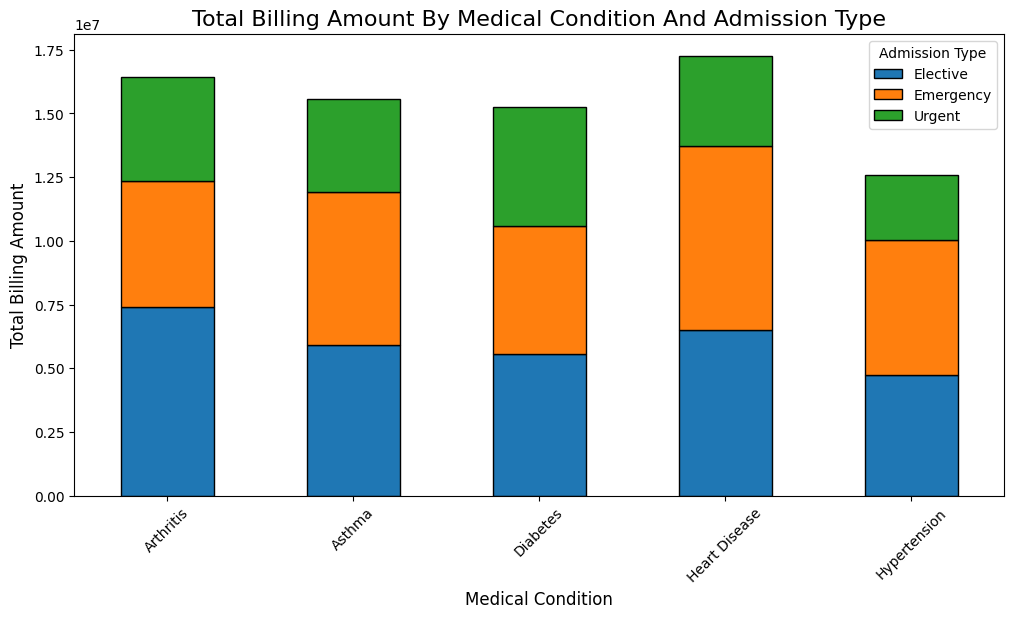

In [ ]:
billing_summary.plot(
    kind='bar',stacked=True,figsize=(12,6),edgecolor='Black'
)
plt.title('Total Billing Amount By Medical Condition And Admission Type',fontsize=16)
plt.xlabel('Medical Condition',fontsize=12)
plt.ylabel('Total Billing Amount',fontsize=12)

plt.xticks(rotation=45)
plt.legend(title='Admission Type')
plt.show()


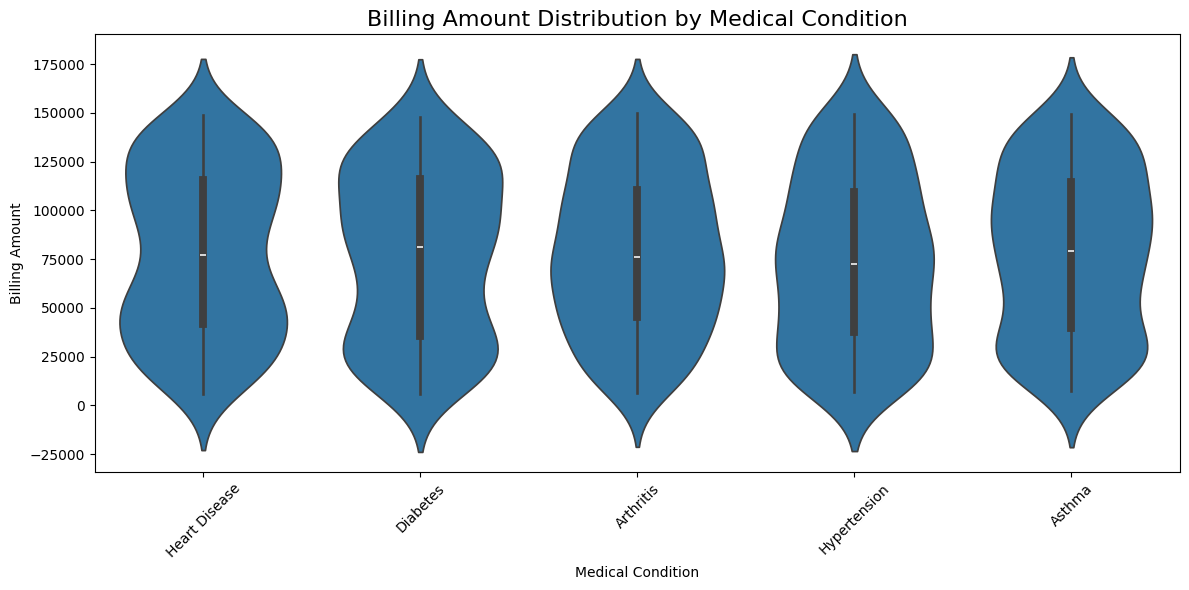

In [ ]:
plt.figure(figsize=(12,6))
sns.violinplot(
    data=df,
    x='Medical_Condition',
    y='Billing_Amount'
)
plt.title('Billing Amount Distribution by Medical Condition',fontsize=16)
plt.xlabel('Medical Condition')
plt.ylabel('Billing Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df['Date_of_Admission'] = pd.to_datetime(df['Date_of_Admission'])

In [ ]:
monthly_admissions =(df.set_index('Date_of_Admission').resample('ME').size())
print(monthly_admissions)

Date_of_Admission
2023-01-31    35
2023-02-28    29
2023-03-31    26
2023-04-30    33
2023-05-31    31
2023-06-30    25
2023-07-31    23
2023-08-31    27
2023-09-30    23
2023-10-31    19
2023-11-30    19
2023-12-31    23
2024-01-31    23
2024-02-29    24
2024-03-31    24
2024-04-30    25
2024-05-31    31
2024-06-30    23
2024-07-31    29
2024-08-31    19
2024-09-30    23
2024-10-31    33
2024-11-30    32
2024-12-31    30
2025-01-31    33
2025-02-28    28
2025-03-31    39
2025-04-30    34
2025-05-31    34
2025-06-30    26
2025-07-31    25
2025-08-31    33
2025-09-30    24
2025-10-31    36
2025-11-30    28
2025-12-31    31
Freq: ME, dtype: int64


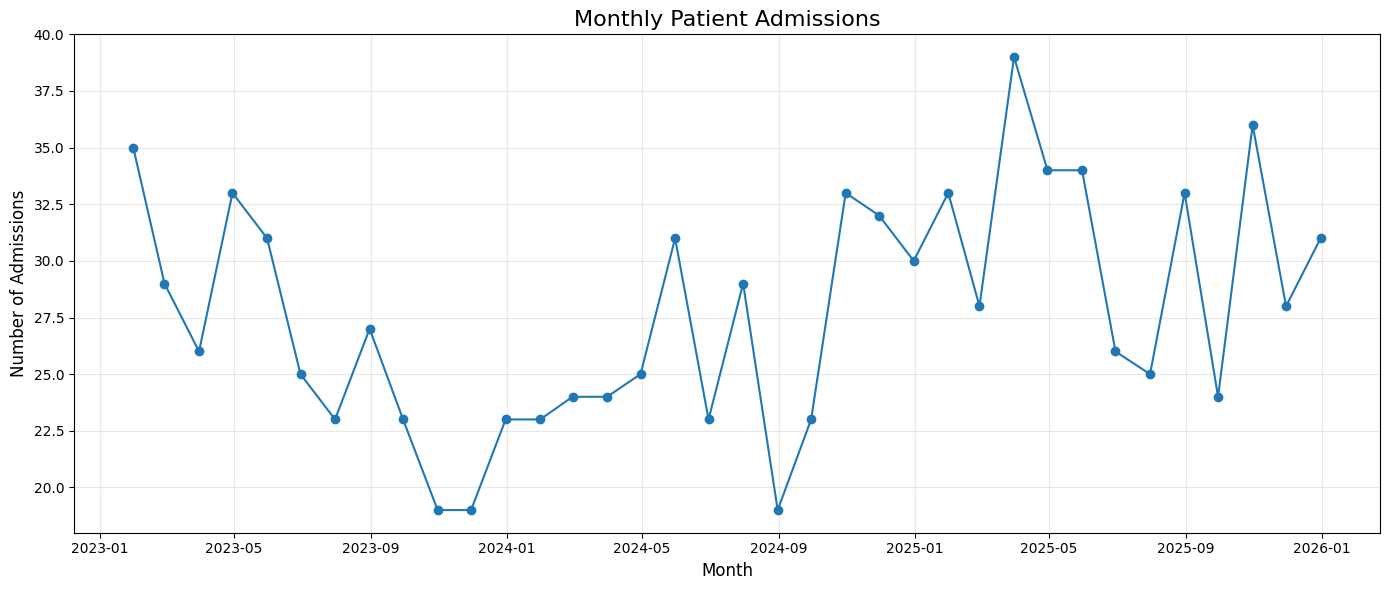

In [ ]:
plt.figure(figsize=(14,6))
plt.plot(monthly_admissions.index,monthly_admissions.values,marker='o')
plt.title('Monthly Patient Admissions',fontsize=16)
plt.xlabel('Month',fontsize=12)
plt.ylabel('Number of Admissions',fontsize=12)
plt.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
numeric_df = df.select_dtypes(
    include="number")

In [ ]:
corr = numeric_df.corr()
corr

,Age,Billing_Amount,Stay_days
Age,1.000000,0.009515,0.019651
Billing_Amount,0.009515,1.000000,-0.040583
Stay_days,0.019651,-0.040583,1.000000


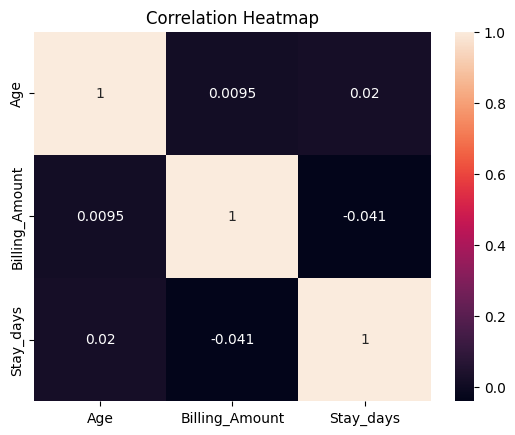

In [ ]:
sns.heatmap(corr,annot=True)
plt.title("Correlation Heatmap")
plt.show()
